# ISO 20414:2020 — Test 7: Overtaking People with Movement Disabilities

Geometry per ISO 20414:2020 Table 8 and Figure 4: room 1 (5 x 4 m), a 12 m x 1,5 m ramp, room 2 (5 x 4 m) and a 1 m exit in the far wall of room 2. Room 1 has two zones. 24 occupants (1.25 m/s) start in Zone 1. Zone 2 is the last 1 m of room 1 at the ramp entrance and holds one occupant. In Scenario 1 this occupant is disabled (e.g. a wheelchair user): 0.8 m/s on horizontal surfaces, 0.4 m/s on the ramp, 0.8 m wide. In Scenario 2 it is like the others (1.25 m/s, radius 0.2 m).

The scenario is built by `standards/utils/movement_disability.py`. It sets the disabled occupant's speed every step from its position, because jupedsim-scenarios 0.7.3 applies speed zones to all agents in the polygon. All other occupants keep 1.25 m/s on the ramp.

Expected result: Zone 1 occupants in Scenario 1 exit later than in Scenario 2. The acceptance criterion compares the **Zone 1 exit times** (last and mean), not the total evacuation time.

In [1]:
from datetime import datetime

print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 16:20 CEST


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle, Rectangle

# The notebook runs from its own directory; the scenario builder lives in standards/utils
sys.path.insert(0, str(Path("..").resolve()))
from utils import movement_disability as md

In [3]:
# House style for the figures below (plain matplotlib: seaborn is not in this environment)
C_S1, C_S2 = "#d73027", "#4575b4"  # Scenario 1 (disability), Scenario 2 (no disability)
LEGEND = {
    "frameon": True,
    "facecolor": "white",
    "framealpha": 0.8,
    "edgecolor": "lightgrey",
    "labelcolor": "dimgrey",
}
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "figure.dpi": 100,
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.color": "#e0e0e0",
        "grid.alpha": 1.0,
        "axes.spines.left": False,
        "axes.spines.bottom": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "normal",
        "axes.titlecolor": "dimgrey",
        "axes.labelcolor": "dimgrey",
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "xtick.labelcolor": "dimgrey",
        "ytick.labelcolor": "dimgrey",
    }
)


def frame_axes(ax):
    ax.patch.set_edgecolor("lightgrey")
    ax.patch.set_linewidth(0.8)

## Run the scenarios

In [4]:
# Scenario 1: zone-2 occupant is disabled. Scenario 2: it is like the others.
result_1 = md.run("iso", disabled=True, seed=42)
result_2 = md.run("iso", disabled=False, seed=42)
layout = result_1.layout
ramp_x0, ramp_x1 = layout.ramp_x
df1, df2 = result_1.trajectory, result_2.trajectory
slow_id, extra_id_s2 = result_1.zone2_id, result_2.zone2_id
slow_exit, extra_exit = result_1.exit_times[slow_id], result_2.exit_times[extra_id_s2]


def first_positions(df, ids):
    first = df[df["id"].isin(ids)].sort_values("time").groupby("id").first()
    return first.loc[ids, ["x", "y"]].to_numpy()


# Agent ids differ between the runs; the 24 Zone 1 agents are paired by order in zone1_ids.
# The same seed gives the same spawn positions, checked here on the first recorded rows.
np.testing.assert_allclose(
    first_positions(df1, result_1.zone1_ids),
    first_positions(df2, result_2.zone1_ids),
    atol=0.05,
)
paired = pd.DataFrame(
    {
        "exit_s1": result_1.zone1_exit_times(),
        "exit_s2": result_2.zone1_exit_times(),
    }
)
print(f"{len(paired)} paired Zone 1 agents; ramp x = {ramp_x0:.2f} to {ramp_x1:.2f} m")

24 paired Zone 1 agents; ramp x = 5.00 to 17.00 m


## Geometry

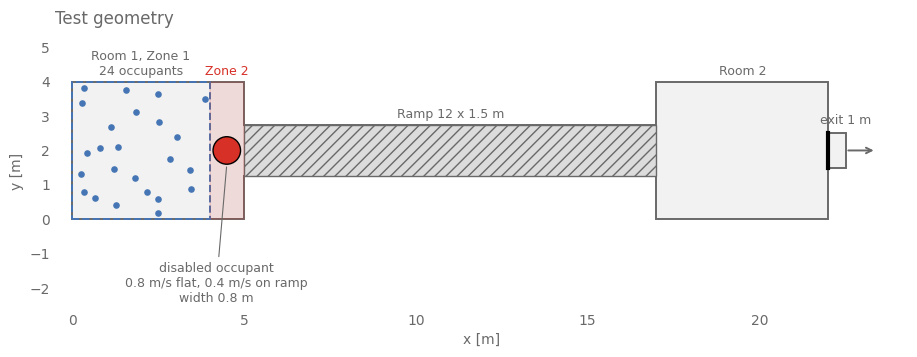

In [5]:
# Geometry (top view), after ISO 20414 Figure 4 / NIST TN 1822 Figure 7
W = md.ROOM_WIDTH
fig, ax = plt.subplots(figsize=(11, 4.2), dpi=100)
ax.set_facecolor("white")
ax.grid(False)
xs, ys = layout.walkable.exterior.xy
ax.fill(xs, ys, facecolor="#f2f2f2", edgecolor="dimgrey", linewidth=1.4, zorder=1)
ax.add_patch(
    Rectangle(
        (ramp_x0, (W - md.RAMP_WIDTH) / 2),
        ramp_x1 - ramp_x0,
        md.RAMP_WIDTH,
        facecolor="#dcdcdc",
        edgecolor="dimgrey",
        hatch="///",
        linewidth=1.0,
        zorder=2,
    )
)
z1 = layout.zone1
ax.add_patch(
    Rectangle(
        (0, 0),
        z1.bounds[2],
        W,
        facecolor="none",
        edgecolor=C_S2,
        linestyle="--",
        linewidth=1.4,
        zorder=3,
    )
)
ax.add_patch(
    Rectangle(
        (z1.bounds[2], 0),
        md.ZONE2_LENGTH,
        W,
        facecolor=C_S1,
        alpha=0.12,
        edgecolor=C_S1,
        linestyle="-",
        linewidth=1.4,
        zorder=3,
    )
)
zx, zy = layout.zone2_position
ax.add_patch(
    Circle((zx, zy), md.DISABLED_RADIUS, facecolor=C_S1, edgecolor="black", zorder=5)
)
rng_pos = first_positions(df2, result_2.zone1_ids)
ax.scatter(rng_pos[:, 0], rng_pos[:, 1], s=14, color=C_S2, zorder=4)
ex = layout.total_length
ax.annotate(
    "",
    xy=(ex + md.DOORWAY_DEPTH + 0.9, W / 2),
    xytext=(ex + md.DOORWAY_DEPTH, W / 2),
    arrowprops={"arrowstyle": "->", "color": "dimgrey", "lw": 1.4},
    annotation_clip=False,
)
ax.plot(
    [ex, ex],
    [(W - md.EXIT_WIDTH) / 2, (W + md.EXIT_WIDTH) / 2],
    color="black",
    linewidth=3,
    zorder=6,
)
kw = {"ha": "center", "va": "bottom", "fontsize": 9, "color": "dimgrey"}
ax.text(z1.bounds[2] / 2, W + 0.12, "Room 1, Zone 1\n24 occupants", **kw)
ax.text(
    z1.bounds[2] + md.ZONE2_LENGTH / 2,
    W + 0.12,
    "Zone 2",
    color=C_S1,
    **{k: v for k, v in kw.items() if k != "color"},
)
ax.text(
    (ramp_x0 + ramp_x1) / 2,
    (W + md.RAMP_WIDTH) / 2 + 0.12,
    f"Ramp{chr(10) if ramp_x1 - ramp_x0 < 5 else ' '}{ramp_x1 - ramp_x0:g} x {md.RAMP_WIDTH:g} m",
    **kw,
)
ax.text(ramp_x1 + md.ROOM_LENGTH / 2, W + 0.12, "Room 2", **kw)
ax.text(
    ex + 0.5,
    W / 2 + 0.7,
    "exit 1 m",
    ha="center",
    va="bottom",
    fontsize=9,
    color="dimgrey",
)
ax.annotate(
    "disabled occupant\n0.8 m/s flat, 0.4 m/s on ramp\nwidth 0.8 m",
    (zx, zy - md.DISABLED_RADIUS),
    xytext=(zx - 0.3, -1.25),
    ha="center",
    va="top",
    fontsize=9,
    color="dimgrey",
    arrowprops={"arrowstyle": "-", "color": "dimgrey", "lw": 0.8},
)
ax.set_xlim(-0.5, ex + md.DOORWAY_DEPTH + 1.8)
ax.set_ylim(-2.6, W + 1.4)
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Test geometry", loc="left", pad=7)
ax.tick_params(axis="both", which="both", length=0, labelcolor="dimgrey")
plt.show()

## Trajectories

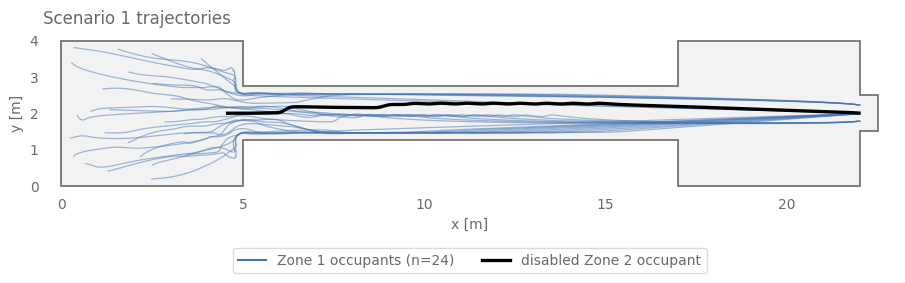

In [6]:
# Plan view of Scenario 1 trajectories, Zone 1 occupants against the disabled occupant
fig, ax = plt.subplots(figsize=(11, 3.2), dpi=100)
ax.grid(False)
xs, ys = layout.walkable.exterior.xy
ax.fill(xs, ys, facecolor="#f2f2f2", edgecolor="dimgrey", linewidth=1.2, zorder=1)
for agent_id, traj in df1.sort_values(["id", "time"]).groupby("id"):
    if agent_id == slow_id:
        continue
    ax.plot(traj["x"], traj["y"], color=C_S2, linewidth=0.9, alpha=0.5, zorder=2)
traj = df1[df1["id"] == slow_id]
ax.plot(traj["x"], traj["y"], color="black", linewidth=2.4, zorder=4)
ax.plot([], [], color=C_S2, linewidth=1.5, label="Zone 1 occupants (n=24)")
ax.plot([], [], color="black", linewidth=2.4, label="disabled Zone 2 occupant")
ax.set_xlim(-0.5, layout.total_length + md.DOORWAY_DEPTH + 0.5)
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Scenario 1 trajectories", loc="left", pad=7)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, **LEGEND)
ax.tick_params(axis="both", which="both", length=0, labelcolor="dimgrey")
plt.show()

## Zone 1 Exit Times

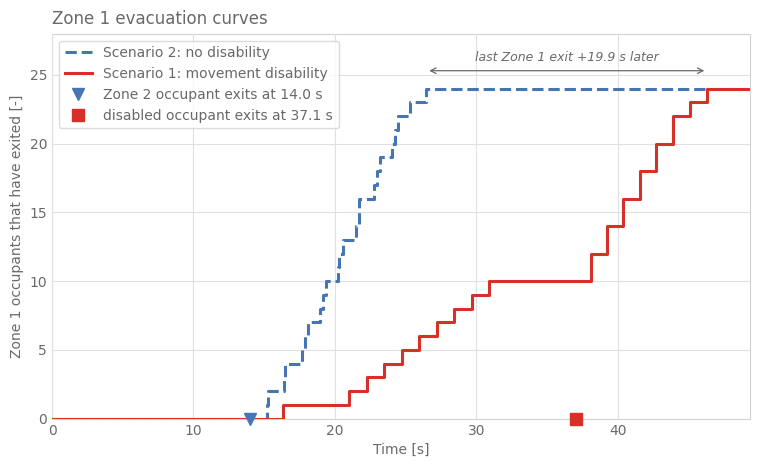

In [7]:
# Figure 1: cumulative Zone 1 exits over time
fig, ax = plt.subplots(figsize=(9, 5), dpi=100)
n1 = len(paired)
t_end = max(paired["exit_s1"].max(), paired["exit_s2"].max()) + 3
for col, color, ls, label in [
    ("exit_s2", C_S2, "--", "Scenario 2: no disability"),
    ("exit_s1", C_S1, "-", "Scenario 1: movement disability"),
]:
    t = np.sort(paired[col].to_numpy())
    ax.step(
        np.r_[0, t, t_end],
        np.r_[0, np.arange(1, n1 + 1), n1],
        where="post",
        color=color,
        linestyle=ls,
        linewidth=2.2,
        label=label,
    )

# Exit time of the Zone 2 occupant, marked on the time axis
for t, color, marker, label in [
    (extra_exit, C_S2, "v", f"Zone 2 occupant exits at {extra_exit:.1f} s"),
    (slow_exit, C_S1, "s", f"disabled occupant exits at {slow_exit:.1f} s"),
]:
    ax.plot(
        t,
        0,
        marker=marker,
        color=color,
        markersize=9,
        clip_on=False,
        zorder=5,
        linestyle="none",
        label=label,
    )

# Insight: gap between the last Zone 1 exits
last1, last2 = paired["exit_s1"].max(), paired["exit_s2"].max()
ax.annotate(
    "",
    xy=(last1, n1 + 1.3),
    xytext=(last2, n1 + 1.3),
    arrowprops={"arrowstyle": "<->", "color": "dimgrey", "lw": 0.9},
)
ax.text(
    (last1 + last2) / 2,
    n1 + 1.8,
    f"last Zone 1 exit {last1 - last2:+.1f} s later",
    ha="center",
    va="bottom",
    fontsize=9,
    color="dimgrey",
    style="italic",
)

ax.set_ylim(0, n1 + 4)
ax.set_xlim(0, t_end)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Zone 1 occupants that have exited [-]")
ax.set_title("Zone 1 evacuation curves", loc="left", pad=7)
ax.legend(loc="upper left", **LEGEND)
ax.tick_params(axis="both", which="both", length=0, labelcolor="dimgrey")
frame_axes(ax)
plt.show()

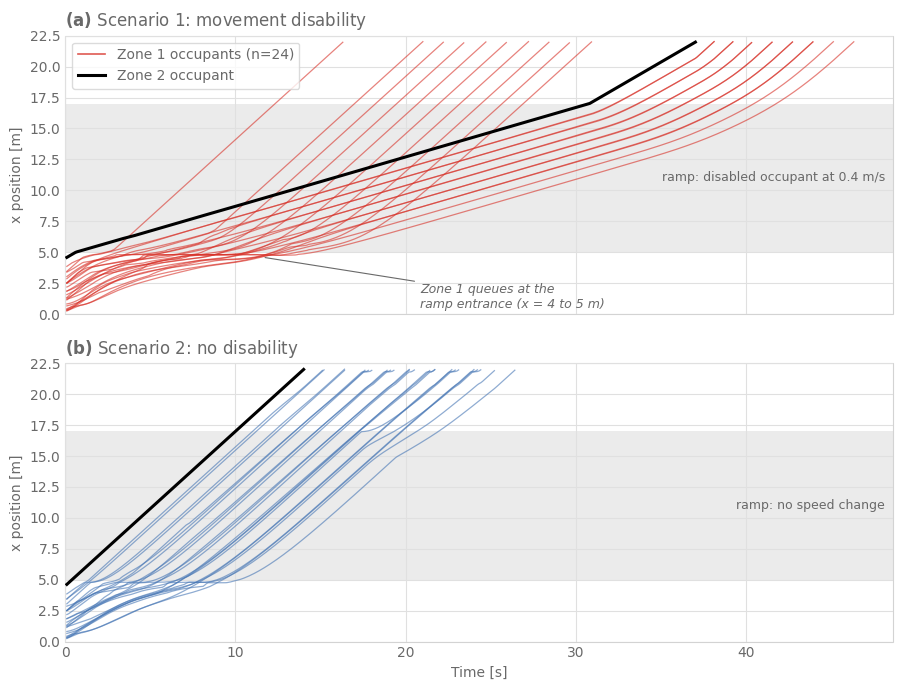

In [8]:
# Figure 2: space-time diagram, x position against time for all agents
xmin, ymin, xmax, ymax = layout.walkable.bounds
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, sharey=True, dpi=100)
for ax, df, color, extra_id, title, ramp_label in [
    (
        axes[0],
        df1,
        C_S1,
        slow_id,
        r"$\bf{(a)}$ Scenario 1: movement disability",
        "ramp: disabled occupant at 0.4 m/s",
    ),
    (
        axes[1],
        df2,
        C_S2,
        extra_id_s2,
        r"$\bf{(b)}$ Scenario 2: no disability",
        "ramp: no speed change",
    ),
]:
    ax.axhspan(ramp_x0, ramp_x1, color="lightgrey", alpha=0.45, zorder=0, linewidth=0)
    ax.text(
        0.99,
        (ramp_x0 + ramp_x1) / 2,
        ramp_label,
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=9,
        color="dimgrey",
    )
    for agent_id, traj in df.groupby("id"):
        if agent_id == extra_id:
            continue
        ax.plot(
            traj["time"], traj["x"], color=color, linewidth=0.9, alpha=0.6, zorder=2
        )
    traj = df[df["id"] == extra_id]
    ax.plot(traj["time"], traj["x"], color="black", linewidth=2.2, zorder=4)
    ax.set_title(title, loc="left", pad=7)
    ax.set_ylabel("x position [m]")
    ax.set_ylim(xmin, xmax)
    ax.set_xlim(0, None)
    ax.tick_params(axis="both", which="both", length=0, labelcolor="dimgrey")
    frame_axes(ax)
axes[1].set_xlabel("Time [s]")
axes[0].legend(
    handles=[
        plt.Line2D(
            [],
            [],
            color=C_S1,
            linewidth=1.2,
            alpha=0.8,
            label="Zone 1 occupants (n=24)",
        ),
        plt.Line2D([], [], color="black", linewidth=2.2, label="Zone 2 occupant"),
    ],
    loc="upper left",
    **LEGEND,
)
t_end = max(df1["time"].max(), df2["time"].max())
axes[0].annotate(
    "Zone 1 queues at the\nramp entrance (x = 4 to 5 m)",
    xy=(0.25 * t_end, 4.6),
    xytext=(0.45 * t_end, 1.4),
    ha="left",
    va="center",
    fontsize=9,
    color="dimgrey",
    style="italic",
    arrowprops={"arrowstyle": "-", "color": "dimgrey", "lw": 0.8},
)
plt.tight_layout()
plt.show()

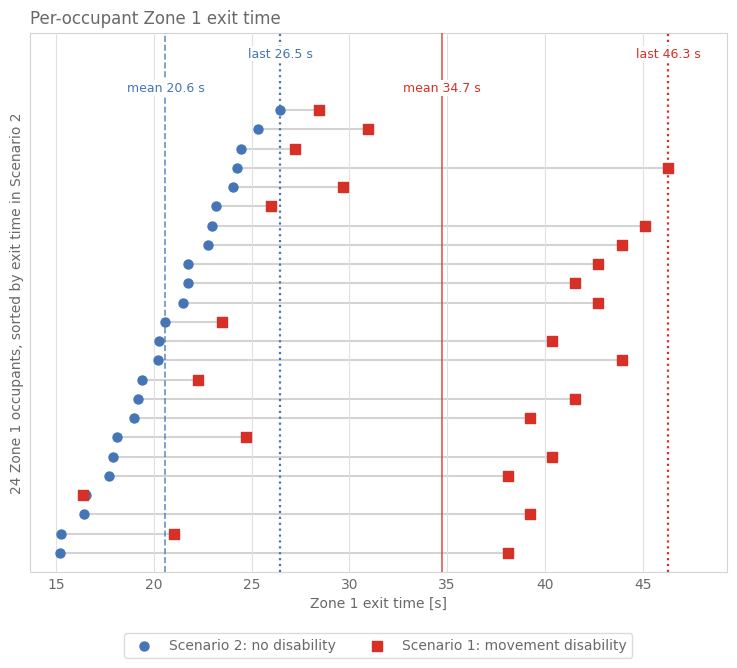

In [9]:
# Figure 3: paired Zone 1 exit times per agent (same spawn position in both scenarios)
order = paired.sort_values("exit_s2").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 7), dpi=100)
y = np.arange(len(order))
ax.hlines(
    y, order["exit_s2"], order["exit_s1"], color="lightgrey", linewidth=1.5, zorder=1
)
ax.scatter(
    order["exit_s2"],
    y,
    color=C_S2,
    marker="o",
    s=42,
    zorder=3,
    label="Scenario 2: no disability",
)
ax.scatter(
    order["exit_s1"],
    y,
    color=C_S1,
    marker="s",
    s=42,
    zorder=3,
    label="Scenario 1: movement disability",
)

for col, color, ls in [("exit_s2", C_S2, "--"), ("exit_s1", C_S1, "-")]:
    ax.axvline(
        paired[col].mean(),
        color=color,
        linestyle=ls,
        linewidth=1.2,
        alpha=0.8,
        zorder=2,
    )
    ax.axvline(paired[col].max(), color=color, linestyle=":", linewidth=1.6, zorder=2)
    for value, kind, row in [
        (paired[col].mean(), "mean", 0.0),
        (paired[col].max(), "last", 1.8),
    ]:
        ax.text(
            value,
            len(order) + row - 0.2,
            f"{kind} {value:.1f} s",
            ha="center",
            va="bottom",
            fontsize=9,
            color=color,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.0},
        )
ax.set_ylim(-1, len(order) + 3)
ax.set_xlim(right=paired.to_numpy().max() + 3)
ax.set_yticks([])
ax.set_xlabel("Zone 1 exit time [s]")
ax.set_ylabel("24 Zone 1 occupants, sorted by exit time in Scenario 2")
ax.set_title("Per-occupant Zone 1 exit time", loc="left", pad=7)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, **LEGEND)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="both", which="both", length=0, labelcolor="dimgrey")
frame_axes(ax)
plt.show()

## Acceptance

Criterion (ISO 20414 Test 7, NIST TN 1822 Verif.2.10): Zone 1 occupants in Scenario 1 exit later than in Scenario 2. Both the last and the mean Zone 1 exit time must be larger in Scenario 1. Exit time is the simulation time at which an agent leaves through the exit.

In [10]:
acceptance = pd.DataFrame(
    {
        "Zone 1 last exit (s)": [paired["exit_s1"].max(), paired["exit_s2"].max()],
        "Zone 1 mean exit (s)": [paired["exit_s1"].mean(), paired["exit_s2"].mean()],
        "Zone 2 occupant exit (s)": [slow_exit, extra_exit],
    },
    index=["Scenario 1 — movement disability", "Scenario 2 — no disability"],
)
display(acceptance.round(2))

assert paired["exit_s1"].max() > paired["exit_s2"].max(), (
    f"Expected last Zone 1 exit in Scenario 1 ({paired['exit_s1'].max():.2f} s) "
    f"to be later than in Scenario 2 ({paired['exit_s2'].max():.2f} s)."
)
assert paired["exit_s1"].mean() > paired["exit_s2"].mean(), (
    f"Expected mean Zone 1 exit in Scenario 1 ({paired['exit_s1'].mean():.2f} s) "
    f"to be later than in Scenario 2 ({paired['exit_s2'].mean():.2f} s)."
)

,Zone 1 last exit (s),Zone 1 mean exit (s),Zone 2 occupant exit (s)
Scenario 1 — movement disability,46.32,34.72,37.05
Scenario 2 — no disability,26.47,20.59,14.03
